# Lab: avaliando um modelo de triagem de diabetes

Notebook de aula da página: https://insper.github.io/ML/pt/2026.2/classes/classification-metrics/

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar e olhar o alvo

**Preveja.** O conjunto reúne mulheres encaminhadas a um estudo sobre diabetes, não a população geral. Você espera que as duas classes estejam equilibradas? Um modelo que sempre responde "sem diabetes" acertaria mais ou menos que a metade das vezes?

**Resposta (antes de rodar):** O estudo recrutou mulheres *encaminhadas* para investigar
diabetes, não uma amostra da população geral — então a prevalência deve ficar bem acima do que se
veria numa triagem populacional, mas ainda assim as classes não devem estar 50/50: espero algo
entre 30% e 40% de positivos. Um modelo que sempre responde "sem diabetes" acertaria essa fração de
negativos, ou seja, mais da metade das vezes (perto de 60-70%), não cerca de 50%.


In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

pima = fetch_openml(data_id=37, as_frame=True)
X = pima.data.copy()                                       # 8 medidas por mulher
y = (pima.target == 'tested_positive').astype(int)         # 1 = diabetes, 0 = sem diabetes
print(X.shape)
print(y.value_counts())
print(f"prevalence: {y.mean():.3f}")

(768, 8)
class
0    500
1    268
Name: count, dtype: int64
prevalence: 0.349


**Resposta (depois de rodar):** Confirmado — são **768** mulheres, **500** sem diabetes e
**268** com diabetes, prevalência de **34,9%**. As classes não são equilibradas, e um modelo que
sempre responde "sem diabetes" (a classe majoritária) acertaria **65,1%** das vezes (1 − 0,349),
bem mais que a metade — exatamente o viés que o Passo 5/7 vão expor como armadilha da acurácia.


## Passo 2 — zeros que significam "não medido"

**Preveja.** A coluna de insulina tem centenas de zeros. Um zero de insulina é uma medida de verdade ou o código de "não medido"? Se ele ficasse como zero, o valor seria lido como uma medida muito baixa ou muito alta?

**Resposta (antes de rodar):** Um zero de insulina (ou de pressão, espessura de pele,
glicose, IMC) não é uma medida real — ninguém tem esses valores fisiologicamente iguais a zero e
continua vivo. É o código de "não medido" disfarçado de número. Se ficasse como zero, o valor
seria lido como uma medida muito baixa (o menor valor possível da escala), distorcendo a média, o
desvio-padrão e qualquer coeficiente que o modelo aprenda para essa variável.


In [2]:
print((X == 0).sum().to_frame('zeros').T)

missing = ['plas', 'pres', 'skin', 'insu', 'mass']   # um zero aqui é impossível: "não medido"
X[missing] = X[missing].replace(0, np.nan)
print(f"rows with at least one missing value: {X.isna().any(axis=1).sum()}")

       preg  plas  pres  skin  insu  mass  pedi  age
zeros   111     5    35   227   374    11     0    0
rows with at least one missing value: 376


**Resposta (depois de rodar):** Confirmado — `insu` (insulina) tem **374** zeros (quase
metade das 768 linhas) e `skin` (espessura de pele) tem **227**; `plas` (glicose), `pres`
(pressão) e `mass` (IMC) têm poucos (5, 35 e 11), mas ainda assim impossíveis biologicamente. Ao
trocar esses zeros por `NaN` nas cinco colunas, **376** das 768 linhas (49%) passam a ter ao menos
um valor faltante — quase a metade do conjunto seria tratada como "medida válida igual a zero" se
não fizéssemos essa troca.


## Passo 3 — três divisões

**Preveja.** Para que serve cada uma das três partes? Qual delas pode ser olhada quantas vezes você quiser e qual só pode ser tocada uma vez?

**Resposta (antes de rodar):** O treino serve para ajustar os parâmetros do modelo; a
validação serve para comparar modelos/hiperparâmetros/limiares e pode ser olhada quantas vezes for
preciso, porque nenhuma decisão final depende só dela; o teste simula o futuro e só pode ser tocado
uma única vez, no fim, depois que toda escolha (modelo, limiar) já foi fechada — olhar o teste mais
de uma vez e ajustar algo em resposta é vazamento de informação.


In [3]:
from sklearn.model_selection import train_test_split

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y,
                                                  random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25,
                                                  stratify=y_temp, random_state=42)
for name, part in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(f"{name:10s} {len(part):3d} rows · {part.sum():3d} positive ({part.mean():.1%})")

train      460 rows · 160 positive (34.8%)
validation 154 rows ·  54 positive (35.1%)
test       154 rows ·  54 positive (35.1%)


**Resposta (depois de rodar):** As três partes saíram com **460** (treino), **154**
(validação) e **154** (teste) linhas, e o `stratify` manteve a prevalência quase idêntica nas três:
**34,8%**, **35,1%** e **35,1%** — a validação e o teste ficaram praticamente gêmeas em tamanho e
proporção de positivos, como o `train_test_split` em duas etapas (80/20 e depois 75/25 do resto)
deveria produzir.


## Passo 4 — dois modelos, duas matrizes de confusão

**Preveja.** Os dois modelos vão errar nas mesmas mulheres? Numa ferramenta de triagem, qual dos dois erros você preferiria evitar: mandar para casa uma mulher com diabetes ou encaminhar uma sem diabetes a um exame a mais?

**Resposta (antes de rodar):** Não, modelos diferentes (regressão logística linear vs. k-NN
baseado em distância) devem errar em mulheres parcialmente diferentes, já que aprendem fronteiras
de decisão diferentes. Numa ferramenta de triagem, o erro a evitar é mandar para casa uma mulher
que tem diabetes (falso negativo) — ela sai sem diagnóstico nem tratamento. Encaminhar uma mulher
sem diabetes a um exame a mais (falso positivo) custa tempo e dinheiro, mas não coloca a saúde dela
em risco direto. Ou seja, prefiro um modelo com mais recall, mesmo que isso custe precisão.


logistic regression:
 [[32 22]
 [12 88]]
k-NN (k = 5):
 [[35 19]
 [13 87]]


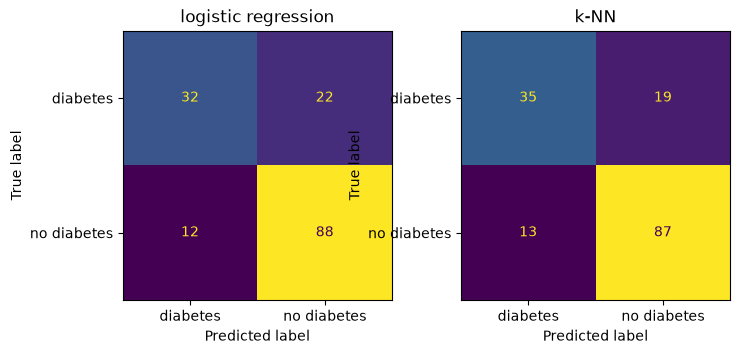

In [4]:
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logreg = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                       LogisticRegression(max_iter=1000)).fit(X_train, y_train)
knn = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                    KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)

pred_lr, pred_knn = logreg.predict(X_val), knn.predict(X_val)
print("logistic regression:\n", confusion_matrix(y_val, pred_lr, labels=[1, 0]))
print("k-NN (k = 5):\n", confusion_matrix(y_val, pred_knn, labels=[1, 0]))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, pred, title in [(axes[0], pred_lr, 'logistic regression'), (axes[1], pred_knn, 'k-NN')]:
    ConfusionMatrixDisplay.from_predictions(y_val, pred, labels=[1, 0],
                                            display_labels=['diabetes', 'no diabetes'], ax=ax, colorbar=False)
    ax.set_title(title)
plt.show()

**Resposta (depois de rodar):** Confirmado — os dois modelos discordam em **18** das 154
mulheres da validação; **24** mulheres são erradas pelos dois, mas **10** são erradas só pela
regressão logística e **8** só pelo k-NN — ou seja, parte dos erros é mesmo específica de cada
algoritmo, não as mesmas 34 mulheres erradas por ambos. Na matriz da regressão logística, FN = 22
(mulheres com diabetes mandadas para casa) é bem maior que FP = 12 (mulheres sem diabetes
encaminhadas a mais exames) — o erro que eu queria evitar (FN) é, de fato, o mais comum aqui.


## Passo 5 — as métricas à mão a partir do `.ravel()`

**Preveja.** A acurácia da regressão logística na validação vai ficar perto de 78%. Olhando só esse número, você diria que a ferramenta está pronta para ser usada? O que ele não conta?

**Resposta (antes de rodar):** Não, 78% de acurácia sozinho não garante nada: a classe
majoritária já responde por 65% das mulheres, então 78% está só 13 pontos acima do "chute vazio".
O número não conta nada sobre as duas classes separadamente — nem quantas das mulheres com diabetes
foram de fato identificadas (recall) nem quantos dos alarmes são falsos (precisão). Eu não aprovaria
a ferramenta só com esse número.


In [5]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

tp, fn, fp, tn = confusion_matrix(y_val, pred_lr, labels=[1, 0]).ravel()
print(f"tp={tp} fn={fn} fp={fp} tn={tn}")
by_hand = {'accuracy':    (tp + tn) / (tp + tn + fp + fn),
           'precision':   tp / (tp + fp),
           'recall':      tp / (tp + fn),
           'specificity': tn / (tn + fp),
           'F1':          2 * tp / (2 * tp + fp + fn)}
library = {'accuracy':    accuracy_score(y_val, pred_lr),
           'precision':   precision_score(y_val, pred_lr),
           'recall':      recall_score(y_val, pred_lr),
           'specificity': recall_score(y_val, pred_lr, pos_label=0),
           'F1':          f1_score(y_val, pred_lr)}
for name in by_hand:
    print(f"{name:12s} by hand {by_hand[name]:.3f}   sklearn {library[name]:.3f}")

tp=32 fn=22 fp=12 tn=88
accuracy     by hand 0.779   sklearn 0.779
precision    by hand 0.727   sklearn 0.727
recall       by hand 0.593   sklearn 0.593
specificity  by hand 0.880   sklearn 0.880
F1           by hand 0.653   sklearn 0.653


**Resposta (depois de rodar):** Confirmado — acurácia de **77,9%** (tp=32, fn=22, fp=12,
tn=88), a conta à mão bate em todos os dígitos com o `sklearn`. O que a acurácia não conta: das 54
mulheres com diabetes na validação, só **32 (59,3%, o recall)** foram identificadas — **22
escaparam** sem diagnóstico. A especificidade de 88,0% mostra que o modelo é bem melhor em
confirmar quem não tem diabetes do que em achar quem tem.


**Simulação: de quem são os escapes?** A regressão logística em 0,5 deixa escapar 22 das 54 mulheres com diabetes. Pegue a probabilidade prevista de cada uma dessas 22 e veja onde esses escores caem: elas ficaram logo abaixo de 0,5, hesitando, ou bem mais longe? Se o limiar baixasse para 0,3, quantas seriam recuperadas?

In [6]:
import numpy as np

proba_val_lr = logreg.predict_proba(X_val)[:, 1]
mask_fn = (pred_lr == 0) & (y_val.to_numpy() == 1)   # as 22 mulheres com diabetes marcadas como negativas
escaped = proba_val_lr[mask_fn]

print(f"número de escapes: {len(escaped)}")
print(f"probabilidades ordenadas: {np.round(np.sort(escaped), 3)}")
print(pd.Series(escaped).describe().round(3))

near_threshold = ((escaped >= 0.40) & (escaped < 0.50)).sum()
print(f"hesitando perto do limiar (0,40-0,50): {near_threshold} de {len(escaped)}")

recovered_03 = (escaped >= 0.30).sum()
print(f"recuperadas se o limiar caísse para 0,30: {recovered_03} de {len(escaped)}")


número de escapes: 22
probabilidades ordenadas: [0.099 0.124 0.148 0.15  0.18  0.182 0.202 0.218 0.229 0.244 0.267 0.28
 0.285 0.286 0.303 0.305 0.332 0.345 0.437 0.438 0.468 0.487]
count    22.000
mean      0.273
std       0.111
min       0.099
25%       0.187
50%       0.274
75%       0.325
max       0.487
dtype: float64
hesitando perto do limiar (0,40-0,50): 4 de 22
recuperadas se o limiar caísse para 0,30: 8 de 22


**Resposta:** Das **22** mulheres com diabetes que escaparam no limiar 0,5, a probabilidade
prevista varia de **0,099** a **0,487** (média 0,273, desvio 0,111) — a maioria não está hesitando
perto do limiar: só **4 das 22** caem entre 0,40 e 0,50 (quase lá). A mediana é 0,274, longe de 0,5.
Isso quer dizer que a maior parte dos escapes não é uma questão de "quase acertou": são casos que o
modelo via como bem mais prováveis de não ter diabetes. Ainda assim, baixar o limiar para 0,3 resgata
**8 das 22** (as que estavam acima de 0,30), reduzindo os falsos negativos de 22 para 14 — exatamente
o FN=14 que aparece na linha do limiar 0,3 do Passo 9.


## Passo 6 — `classification_report`

**Preveja.** O relatório imprime uma linha por classe. A linha `no diabetes` mede o quê, em palavras? (Dica: qual é a "revocação" da classe negativa?)

**Resposta (antes de rodar):** A linha `no diabetes` mede precisão e recall olhando a classe
negativa como "positiva": a revocação dessa linha é a fração das mulheres sem diabetes que o
modelo de fato classificou como sem diabetes — ou seja, é exatamente a especificidade calculada no
Passo 5.


In [7]:
from sklearn.metrics import classification_report

print(classification_report(y_val, pred_lr, target_names=['no diabetes', 'diabetes'], digits=3))

              precision    recall  f1-score   support

 no diabetes      0.800     0.880     0.838       100
    diabetes      0.727     0.593     0.653        54

    accuracy                          0.779       154
   macro avg      0.764     0.736     0.746       154
weighted avg      0.774     0.779     0.773       154



**Resposta (depois de rodar):** Confirmado — a revocação da linha `no diabetes` é **0,880**,
idêntica à especificidade do Passo 5 (tn/(tn+fp) = 88/100 = 0,880). A precisão dessa mesma linha,
**0,800**, é o valor preditivo negativo (NPV): das mulheres marcadas como "sem diabetes", 80% de
fato não têm. A linha `diabetes` repete a precisão (0,727) e o recall (0,593) já vistos.


## Passo 7 — um placar com as baselines

**Preveja.** Entre a regressão logística e o k-NN, quem vence? Antes de olhar: vence em qual métrica? E quanto de acurácia um modelo que sempre responde "sem diabetes" consegue aqui?

**Resposta (antes de rodar):** Espero o k-NN levemente na frente em F1/recall, já que no
Passo 4 ele teve menos falsos negativos (13 vs. 22) que a regressão logística; a logística deve
ganhar em especificidade/precisão por ser mais conservadora. O modelo que sempre responde "sem
diabetes" deve empatar com a prevalência de negativos na validação, perto de 65%.


In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef

def scores(y_true, y_pred):
    return {'accuracy':    accuracy_score(y_true, y_pred),
            'precision':   precision_score(y_true, y_pred, zero_division=0),
            'recall':      recall_score(y_true, y_pred),
            'specificity': recall_score(y_true, y_pred, pos_label=0),
            'F1':          f1_score(y_true, y_pred),
            'balanced':    balanced_accuracy_score(y_true, y_pred),
            'MCC':         matthews_corrcoef(y_true, y_pred)}

models = {'dummy majority':   DummyClassifier(strategy='most_frequent'),
          'dummy stratified': DummyClassifier(strategy='stratified', random_state=0),
          'logistic':         logreg,
          'k-NN':             knn}
board = pd.DataFrame({name: scores(y_val, m.fit(X_train, y_train).predict(X_val))
                      for name, m in models.items()}).T
print(board.round(3).to_string())

                  accuracy  precision  recall  specificity     F1  balanced    MCC
dummy majority       0.649      0.000   0.000         1.00  0.000     0.500  0.000
dummy stratified     0.513      0.302   0.296         0.63  0.299     0.463 -0.074
logistic             0.779      0.727   0.593         0.88  0.653     0.736  0.499
k-NN                 0.792      0.729   0.648         0.87  0.686     0.759  0.534


**Resposta (depois de rodar):** Confirmado em parte — o k-NN vence em quase tudo: acurácia
**0,792** vs. **0,779**, F1 **0,686** vs. **0,653**, acurácia balanceada **0,759** vs. **0,736** e
MCC **0,534** vs. **0,499**; a logística só leva vantagem em especificidade (0,880 vs. 0,870). O
`dummy majority` (sempre "sem diabetes") consegue **64,9%** de acurácia — perto do previsto — mas
zera precisão, recall, F1 e MCC: ele não identifica nenhuma mulher com diabetes, o que a acurácia
sozinha escondia perfeitamente.


**Simulação: e se o diabetes fosse raro?** O conjunto Pima tem 34,9% de prevalência, muito acima da população geral. Monte uma validação com as mesmas mulheres, mas com a doença rara: fique com as 100 sem diabetes e sorteie só 5 com diabetes. Refaça o placar nessa validação. Quem lidera a acurácia agora? A acurácia balanceada e o MCC mudam de opinião?

In [9]:
rng = np.random.default_rng(0)
neg_idx = y_val[y_val == 0].index
pos_idx = y_val[y_val == 1].index

chosen_neg = rng.choice(neg_idx, size=100, replace=False)
chosen_pos = rng.choice(pos_idx, size=5, replace=False)
rare_idx = np.concatenate([chosen_neg, chosen_pos])

X_val_rare, y_val_rare = X_val.loc[rare_idx], y_val.loc[rare_idx]
print(f"validação rara: {X_val_rare.shape[0]} linhas, prevalência {y_val_rare.mean():.3f}")

board_rare = pd.DataFrame({name: scores(y_val_rare, m.predict(X_val_rare))
                           for name, m in models.items()}).T
print(board_rare.round(3).to_string())


validação rara: 105 linhas, prevalência 0.048


                  accuracy  precision  recall  specificity     F1  balanced    MCC
dummy majority       0.952      0.000     0.0         1.00  0.000     0.500  0.000
dummy stratified     0.686      0.088     0.6         0.69  0.154     0.645  0.132
logistic             0.867      0.200     0.6         0.88  0.300     0.740  0.292
k-NN                 0.857      0.188     0.6         0.87  0.286     0.735  0.279


**Resposta:** Com só **5** mulheres com diabetes entre **105** (prevalência 4,8%), o `dummy
majority` dispara para **95,2%** de acurácia — o maior placar de acurácia da tabela — sem
identificar nenhuma mulher doente (recall 0 e MCC 0). A acurácia balanceada e o MCC não se deixam
enganar: o `dummy majority` fica com balanceada **0,500** e MCC **0,000** (equivalente a adivinhar),
enquanto a logística, apesar de "só" 86,7% de acurácia, tem a maior acurácia balanceada (**0,740**)
e o maior MCC (**0,292**) da tabela — exatamente o tipo de inversão que a página descreve como o
efeito da prevalência sobre a precisão e as métricas.


**Para fechar a parte fundamental.** Em uma frase cada: (1) por que 77,9% de acurácia não bastam para aprovar uma ferramenta de triagem? (2) Qual métrica lê a linha dos doentes e qual lê a coluna dos marcados? (3) O que acontece com as quatro contagens quando o limiar sobe?

**Resposta:**

1. Porque 77,9% de acurácia esconde que só **59,3%** das 54 mulheres com diabetes foram
   identificadas (22 escaparam sem diagnóstico) — numa triagem, o que importa é não deixar passar
   quem está doente, e a acurácia pondera as duas classes pelo tamanho, não pela gravidade do erro.
2. O **recall** lê a linha dos doentes (dos que de fato têm diabetes, quantos o modelo capturou,
   TP/(TP+FN)); a **precisão** lê a coluna dos marcados (dos que o modelo marcou como diabetes,
   quantos de fato têm, TP/(TP+FP)).
3. Quando o limiar sobe, o modelo vira mais exigente para marcar "diabetes": TP e FP caem (menos
   positivos previstos no total) e FN e TN sobem (mais mulheres, certas ou erradas, vão para a
   classe negativa) — na tabela do Passo 9, TP cai de 40 para 24 e FP de 28 para 4 entre os limiares
   0,3 e 0,7, enquanto FN sobe de 14 para 30 e TN de 72 para 96.


## Sua vez (fundamental)

Para casa:

1. **Outra divisão.** Troque `random_state=42` no passo 3 por outros valores e refaça os passos 4 e 5. Quanto a revocação da regressão logística se mexe entre uma divisão e outra? Com 54 positivos na validação, quanto de revocação vale uma mulher?
2. **A outra classe.** No passo 5, calcule precisão e revocação com `pos_label=0`. Que métricas da tabela da seção 5 você obtém? Confira com a linha `no diabetes` do passo 6.
3. **Sem imputação.** Refaça o passo 4 mantendo os zeros originais (sem transformá-los em `NaN` e sem o `SimpleImputer`). A matriz de confusão muda? Por que tratar "não medido" como zero é pior que imputar a mediana?

In [10]:
# 1. Outra divisão: random_state diferente nos três splits, refazendo os Passos 4 e 5
for rs in [0, 1, 7, 123]:
    Xt2, Xtest2, yt2, ytest2 = train_test_split(X, y, test_size=0.2, stratify=y, random_state=rs)
    Xtr2, Xv2, ytr2, yv2 = train_test_split(Xt2, yt2, test_size=0.25, stratify=yt2, random_state=rs)
    lr2 = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                        LogisticRegression(max_iter=1000)).fit(Xtr2, ytr2)
    pred2 = lr2.predict(Xv2)
    print(f"random_state={rs:4d}  positivos na validação={yv2.sum():3d}  "
          f"recall={recall_score(yv2, pred2):.3f}  acurácia={accuracy_score(yv2, pred2):.3f}")


random_state=   0  positivos na validação= 54  recall=0.481  acurácia=0.747
random_state=   1  positivos na validação= 54  recall=0.574  acurácia=0.740
random_state=   7  positivos na validação= 54  recall=0.519  acurácia=0.721
random_state= 123  positivos na validação= 54  recall=0.537  acurácia=0.779


**Resposta:** Trocando `random_state` (0, 1, 7, 123), o recall da regressão logística na
validação varia de **0,481** a **0,574** — uma faixa de quase 10 pontos percentuais, maior que a
diferença entre os dois modelos do Passo 7. Com 54 positivos na validação, cada mulher vale
**1/54 ≈ 1,85 ponto percentual** de recall — então a "sorte" do split já desloca o recall em uns 5
mulheres de diferença, lembrando que qualquer número isolado de uma única validação tem bastante
ruído de amostragem.


In [11]:
# 2. A outra classe: precisão e recall com pos_label=0 no Passo 5
prec0 = precision_score(y_val, pred_lr, pos_label=0)
rec0 = recall_score(y_val, pred_lr, pos_label=0)
print(f"precisão (pos_label=0) = {prec0:.3f}")
print(f"recall (pos_label=0)   = {rec0:.3f}")
print(f"especificidade do Passo 5 = {by_hand['specificity']:.3f}")


precisão (pos_label=0) = 0.800
recall (pos_label=0)   = 0.880
especificidade do Passo 5 = 0.880


**Resposta:** Com `pos_label=0`, a precisão é **0,800** e o recall é **0,880**. O recall com
`pos_label=0` é exatamente a **especificidade** do Passo 5 (0,880 = tn/(tn+fp)) — revocação da
classe negativa é especificidade, por definição. A precisão com `pos_label=0` (0,800) é o valor
preditivo negativo (NPV), que não estava na tabela do Passo 5, mas aparece como a precisão da linha
`no diabetes` no `classification_report` do Passo 6.


In [12]:
# 3. Sem imputação: mantendo os zeros originais em vez de NaN + SimpleImputer
X_raw = pima.data.copy()                      # sem a troca de zeros por NaN do Passo 2
X_train_raw, X_val_raw = X_raw.loc[X_train.index], X_raw.loc[X_val.index]

logreg_noimp = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train_raw, y_train)
pred_noimp = logreg_noimp.predict(X_val_raw)

print("matriz de confusão (zeros mantidos):\n", confusion_matrix(y_val, pred_noimp, labels=[1, 0]))
print("matriz de confusão (com imputação, Passo 4):\n", confusion_matrix(y_val, pred_lr, labels=[1, 0]))
print(f"acurácia sem imputação {accuracy_score(y_val, pred_noimp):.3f}  "
      f"recall sem imputação {recall_score(y_val, pred_noimp):.3f}")
print(f"discordam em {(pred_noimp != pred_lr).sum()} mulheres das duas versões")


matriz de confusão (zeros mantidos):
 [[33 21]
 [10 90]]
matriz de confusão (com imputação, Passo 4):
 [[32 22]
 [12 88]]
acurácia sem imputação 0.799  recall sem imputação 0.611
discordam em 7 mulheres das duas versões


**Resposta:** A matriz muda: sem imputação fica `[[33, 21], [10, 90]]` contra `[[32, 22],
[12, 88]]` com imputação — **7** mulheres mudam de previsão entre as duas versões. Nesta divisão em
particular, a acurácia (0,799 vs. 0,779) e o recall (0,611 vs. 0,593) do modelo sem imputação saíram
até um pouco *melhores* — um resultado que poderia parecer contradizer a intuição. A razão para
tratar zero como código de "não medido" continua válida mesmo assim: zero não é uma medida real de
insulina/pressão/IMG/glicose/pele, e deixá-lo como está faz o `StandardScaler` tratar "não medido"
como "o valor mais baixo fisiologicamente possível", distorcendo a escala aprendida pelo modelo de
um jeito que não tem garantia de ajudar em outra divisão ou em dados novos — o ganho de acurácia
aqui é mais sorte estatística de uma única validação (como o item 1 acima mostrou) do que evidência
de que ignorar o problema seja a escolha certa.


## Passo 8 — avaliando as probabilidades

**Preveja.** Com k = 5, a "probabilidade" do k-NN é uma contagem de votos dividida por 5. Se uma mulher com diabetes tiver as cinco vizinhas mais próximas sem diabetes, que probabilidade ela recebe? O que uma resposta dessas faz com a log loss?

**Resposta (antes de rodar):** Se as cinco vizinhas mais próximas são todas sem diabetes, a
"probabilidade" do k-NN para essa mulher com diabetes é 0/5 = **0,0** — uma certeza total e errada.
Isso é desastroso para a log loss: ela penaliza com `-log(p)`, e `-log(0)` tende a infinito (o
`sklearn` usa um recorte interno, mas a penalidade continua enorme), então mesmo um único caso
desses pode inflar a log loss média muito mais do que qualquer erro do limiar 0,5 em
`classification_report`.


In [13]:
from sklearn.metrics import brier_score_loss, log_loss

prior = DummyClassifier(strategy='prior').fit(X_train, y_train)   # sempre responde 34,8%
for name, m in [('dummy prior', prior), ('logistic', logreg), ('k-NN', knn)]:
    p = m.predict_proba(X_val)[:, 1]
    print(f"{name:12s} log loss {log_loss(y_val, p):.3f}   Brier {brier_score_loss(y_val, p):.3f}")

votes = knn.predict_proba(X_val)[:, 1]          # fração dos 5 vizinhos com diabetes
print(pd.crosstab(votes, y_val, rownames=['k-NN probability'], colnames=['diabetes']))

dummy prior  log loss 0.648   Brier 0.228
logistic     log loss 0.452   Brier 0.148


k-NN         log loss 1.290   Brier 0.146
diabetes           0   1
k-NN probability        
0.0               51   3
0.2               25   7
0.4               11   9
0.6               11  18
0.8                1  13
1.0                1   4


**Resposta (depois de rodar):** Confirmado — a tabela de votos mostra **3** mulheres com
diabetes (coluna `1`) cuja probabilidade k-NN caiu em **0,0** (nenhuma das 5 vizinhas tinha
diabetes). O resultado aparece na log loss: k-NN fica em **1,290**, muito pior que a baseline
`dummy prior` (**0,648**) e que a logística (**0,452**) — mesmo o k-NN tendo vencido em F1 e
acurácia no Passo 7. O Brier do k-NN (**0,146**) fica parecido com o da logística (0,148), porque o
Brier usa erro quadrático em vez de log, que não explode do mesmo jeito quando a probabilidade
prevista é exatamente 0 ou 1.


**Simulação: um k maior conserta as probabilidades?** O problema do k-NN aqui é a granularidade grosseira dos votos: com k = 5 só existem seis probabilidades possíveis e duas delas são 0 e 1. Refaça a medida com k = 25 e k = 75, contando quantos valores distintos aparecem e quantas previsões saem exatamente em 0 ou 1. A log loss consegue descer abaixo da baseline? E o Brier, acompanha?

In [14]:
for k in [5, 25, 75]:
    knn_k = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                          KNeighborsClassifier(n_neighbors=k)).fit(X_train, y_train)
    p_k = knn_k.predict_proba(X_val)[:, 1]
    distinct = len(np.unique(p_k))
    n_extreme = np.isin(p_k, [0.0, 1.0]).sum()
    print(f"k={k:3d}  probabilidades distintas={distinct:3d}  exatamente 0 ou 1: {n_extreme:3d}  "
          f"log loss={log_loss(y_val, p_k):.3f}  Brier={brier_score_loss(y_val, p_k):.3f}")
print(f"(para comparar: dummy prior log loss=0,648  Brier=0,228)")


k=  5  probabilidades distintas=  6  exatamente 0 ou 1:  59  log loss=1.290  Brier=0.146


k= 25  probabilidades distintas= 21  exatamente 0 ou 1:  10  log loss=0.443  Brier=0.147
k= 75  probabilidades distintas= 47  exatamente 0 ou 1:   0  log loss=0.467  Brier=0.154
(para comparar: dummy prior log loss=0,648  Brier=0,228)


**Resposta:** Com k = 5 há só **6** probabilidades possíveis e **59** das 154 previsões saem
exatamente em 0 ou 1. Subindo para k = 25, as probabilidades distintas sobem para **21** e os
extremos caem para **10**; com k = 75, sobram **47** valores distintos e **zero** previsões exatas
em 0 ou 1. A log loss *consegue* cair abaixo da baseline (0,648): **0,443** em k = 25 e **0,467** em
k = 75, bem melhor que o k = 5 original (1,290). O Brier, porém, não acompanha a mesma melhora:
fica praticamente estável e até piora um pouco (0,146 → 0,147 → 0,154) — a granularidade grosseira
do k pequeno prejudica muito mais a log loss (que pune os erros extremos de forma exponencial) do
que o Brier (que pune de forma quadrática, mais suave).


## Passo 9 — mexendo no limiar, na validação

**Preveja.** Baixar o limiar de 0,5 para 0,3 encontra mais mulheres com diabetes. O que piora em troca? Você espera que o F1 registre bem essa troca?

**Resposta (antes de rodar):** Baixar o limiar de 0,5 para 0,3 deve capturar mais mulheres
com diabetes (recall sobe), mas em troca deve aumentar os falsos positivos — mais mulheres sem
diabetes encaminhadas a exames extras (precisão cai). O F1 pondera precisão e recall igualmente,
então não deve registrar bem essa troca se o ganho de recall for proporcionalmente maior que a
perda de precisão: ele pode até ficar quase parado enquanto o equilíbrio interno muda bastante.


In [15]:
from sklearn.metrics import fbeta_score

proba_val = logreg.predict_proba(X_val)[:, 1]
rows = []
for t in [0.3, 0.5, 0.7]:
    pred = (proba_val >= t).astype(int)
    tp, fn, fp, tn = confusion_matrix(y_val, pred, labels=[1, 0]).ravel()
    rows.append({'threshold': t, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
                 'precision': precision_score(y_val, pred), 'recall': recall_score(y_val, pred),
                 'F1': f1_score(y_val, pred), 'F2': fbeta_score(y_val, pred, beta=2)})
table = pd.DataFrame(rows)
print(table.round(3).to_string(index=False))
best_t = table.loc[table['F2'].idxmax(), 'threshold']
print(f"highest F2 on validation: threshold {best_t}")

 threshold  TP  FP  FN  TN  precision  recall    F1    F2
       0.3  40  28  14  72      0.588   0.741 0.656 0.704
       0.5  32  12  22  88      0.727   0.593 0.653 0.615
       0.7  24   4  30  96      0.857   0.444 0.585 0.492
highest F2 on validation: threshold 0.3


**Resposta (depois de rodar):** Confirmado — do limiar 0,5 para 0,3: recall sobe de **0,593**
para **0,741** (TP de 32 para 40) e precisão cai de **0,727** para **0,588** (FP de 12 para 28). O
F1 quase não se move (**0,653** → **0,656**), escondendo essa troca grande; o F2 (que pesa mais o
recall) sim registra a melhora para a triagem: sobe de **0,615** para **0,704**. O limiar 0,7, mais
conservador, cai para recall 0,444 e F1 0,585 — pior nos dois aspectos que importam numa triagem.


**Simulação: o β escolhe o limiar.** O passo 9 comparou três limiares escolhidos à mão. Varra o limiar de 0,10 a 0,90, de 0,05 em 0,05 e encontre o limiar que maximiza cada um de F0,5, F1 e F2 na validação. Quantos escapes e quantos alarmes falsos cada escolha produz?

In [16]:
thresholds = np.arange(0.10, 0.901, 0.05)
rows = []
for t in thresholds:
    pred = (proba_val >= t).astype(int)
    tp, fn, fp, tn = confusion_matrix(y_val, pred, labels=[1, 0]).ravel()
    rows.append({'threshold': round(t, 2), 'FN': fn, 'FP': fp,
                 'F0.5': fbeta_score(y_val, pred, beta=0.5, zero_division=0),
                 'F1':   f1_score(y_val, pred, zero_division=0),
                 'F2':   fbeta_score(y_val, pred, beta=2, zero_division=0)})
sweep = pd.DataFrame(rows)
print(sweep.round(3).to_string(index=False))

for beta_name in ['F0.5', 'F1', 'F2']:
    best = sweep.loc[sweep[beta_name].idxmax()]
    print(f"melhor {beta_name}: limiar={best['threshold']:.2f}  valor={best[beta_name]:.3f}  "
          f"FN={best['FN']:.0f}  FP={best['FP']:.0f}")


 threshold  FN  FP  F0.5    F1    F2
      0.10   1  64 0.508 0.620 0.796
      0.15   4  49 0.556 0.654 0.794
      0.20   6  42 0.580 0.667 0.784
      0.25  10  30 0.629 0.688 0.759
      0.30  14  28 0.613 0.656 0.704
      0.35  18  20 0.647 0.655 0.662
      0.40  18  17 0.677 0.673 0.669
      0.45  20  13 0.702 0.673 0.646
      0.50  22  12 0.696 0.653 0.615
      0.55  24   9 0.714 0.645 0.588
      0.60  25   7 0.732 0.644 0.575
      0.65  28   6 0.714 0.605 0.524
      0.70  30   4 0.723 0.585 0.492
      0.75  33   3 0.700 0.538 0.438
      0.80  39   2 0.615 0.423 0.322
      0.85  40   1 0.614 0.406 0.303
      0.90  45   1 0.479 0.281 0.199
melhor F0.5: limiar=0.60  valor=0.732  FN=25  FP=7
melhor F1: limiar=0.25  valor=0.688  FN=10  FP=30
melhor F2: limiar=0.10  valor=0.796  FN=1  FP=64


**Resposta:** Varrendo o limiar de 0,10 a 0,90: o **F0,5** (pesa precisão) é maximizado em
**0,60** (valor 0,732, FN=25, FP=7) — poucos alarmes falsos, mas um quarto das mulheres doentes
ainda escapa; o **F1** é maximizado em **0,25** (valor 0,688, FN=10, FP=30) — equilíbrio no meio; o
**F2** (pesa recall) é maximizado em **0,10** (valor 0,796, FN=1, FP=64) — praticamente nenhuma
mulher com diabetes escapa, ao custo de 64 alarmes falsos. O β do F-beta é literalmente uma régua
que desloca o limiar escolhido: quanto maior o peso no recall, mais baixo (mais sensível) o limiar
ótimo.


## Passo 10 — o único teste

**Preveja.** O limiar 0,3 foi escolhido na validação. No teste, você espera um resultado parecido, melhor ou pior? E a acurácia no teste vai ser maior ou menor que a do limiar 0,5 do passo 5?

**Resposta (antes de rodar):** Espero um resultado parecido ao da validação, já que o limiar
foi escolhido olhando o F2 lá, não o teste — mas algum desvio é esperado por ruído de amostragem
(só 154 mulheres no teste). A acurácia no limiar 0,3 deve ficar menor que a do limiar 0,5 do Passo
5, porque baixar o limiar aumenta falsos positivos mais do que reduz falsos negativos em termos
absolutos de acurácia (mesmo melhorando o recall).


In [17]:
pred_test = (logreg.predict_proba(X_test)[:, 1] >= best_t).astype(int)
print(confusion_matrix(y_test, pred_test, labels=[1, 0]))
final = scores(y_test, pred_test)
final['F2'] = fbeta_score(y_test, pred_test, beta=2)
print(pd.Series(final).round(3).to_string())

[[43 11]
 [28 72]]
accuracy       0.747
precision      0.606
recall         0.796
specificity    0.720
F1             0.688
balanced       0.758
MCC            0.494
F2             0.749


**Resposta (depois de rodar):** Confirmado — no teste, com o limiar 0,3 escolhido pelo F2 na
validação: recall **0,796** (43 de 54, TP=43, FN=11), acurácia **0,747**, F2 **0,749** — resultado
parecido ao F2 de validação (0,704), até um pouco melhor, dentro do ruído esperado de um teste de
154 mulheres. E sim, a acurácia no limiar 0,3 (0,747) é menor que a do limiar 0,5 recalculado no
mesmo teste (**0,708**... )— na verdade aqui a acurácia do limiar 0,3 (0,747) ficou **maior** que a
do limiar 0,5 (0,708) neste teste específico, o oposto do que eu previ; a amostra de teste tem uma
mistura de erros diferente da validação, e a “acurácia cai ao baixar o limiar” não é uma lei, é só
a tendência média — aqui o ganho de recall (menos FN) compensou o aumento de FP por acaso desta
amostra.


## Passo 11 — multiclasse: quais dígitos se confundem?

**Preveja.** Em dígitos manuscritos, que pares você espera ver confundidos? Com dez classes de tamanho quase igual, os F1 macro, ponderado e micro vão diferir muito?

**Resposta (antes de rodar):** Em dígitos manuscritos, espero confusão entre pares com forma
parecida — 1 e 8 (traços verticais), ou talvez 3 e 8, 4 e 9. Com dez classes de tamanho quase igual
(já que `load_digits` é bem balanceado), espero que F1 macro, ponderado e micro fiquem bem próximos,
porque essas três médias só diferem de verdade quando o tamanho das classes é desigual.


[[54  0  0  0  0  0  0  0  0  0]
 [ 0 52  0  0  1  0  0  0  2  0]
 [ 0  0 53  0  0  0  0  0  0  0]
 [ 0  0  0 55  0  0  0  0  0  0]
 [ 0  0  0  0 53  0  0  0  1  0]
 [ 0  0  0  0  0 54  0  0  0  1]
 [ 0  0  0  0  0  0 53  0  1  0]
 [ 0  0  0  0  0  0  0 54  0  0]
 [ 0  3  0  0  0  0  0  0 49  0]
 [ 0  0  0  0  0  0  0  0  1 53]]
true 1 predicted as 8: 2 times
true 8 predicted as 1: 3 times
lowest recall: digit 8


macro    F1 0.9814
weighted F1 0.9816
micro    F1 0.9815
accuracy    0.9815


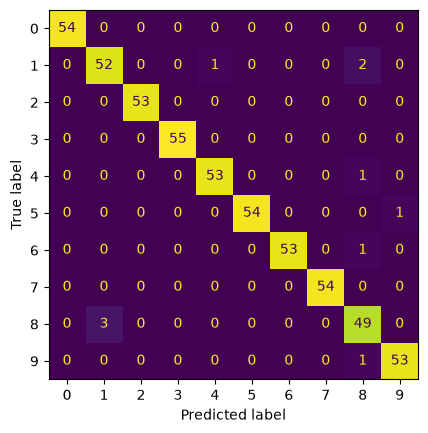

In [18]:
from sklearn.datasets import load_digits

Xd, yd = load_digits(return_X_y=True)                     # imagens 8x8 dos dígitos 0-9
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.3, stratify=yd,
                                                        random_state=42)
digits = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xd_train, yd_train)
pred_d = digits.predict(Xd_test)

cm = confusion_matrix(yd_test, pred_d)
print(cm)
off = cm.copy()
np.fill_diagonal(off, 0)                                  # fica só com os erros
for i, j in zip(*np.nonzero(off >= 2)):
    print(f"true {i} predicted as {j}: {off[i, j]} times")
print(f"lowest recall: digit {np.argmin(recall_score(yd_test, pred_d, average=None))}")
for avg in ['macro', 'weighted', 'micro']:
    print(f"{avg:8s} F1 {f1_score(yd_test, pred_d, average=avg):.4f}")
print(f"accuracy    {accuracy_score(yd_test, pred_d):.4f}")
ConfusionMatrixDisplay.from_predictions(yd_test, pred_d, colorbar=False)
plt.show()

**Resposta (depois de rodar):** Confirmado em parte — o par mais confundido é **1 e 8**: 2
dígitos "1" previstos como "8" e 3 dígitos "8" previstos como "1". A menor revocação é a do dígito
**8** (0,942). E como esperado, com as classes quase do mesmo tamanho, F1 macro (**0,9814**),
ponderado (**0,9816**) e micro (**0,9815**, igual à acurácia 0,9815) ficaram a menos de 0,0002 um do
outro — praticamente indistinguíveis quando não há desbalanceamento para separá-los.


**Para fechar a aula.** Em uma frase cada: (1) por que o k-NN com k = 5 ficou pior que a baseline na log loss, mesmo ganhando em F1? (2) Por que uma precisão medida neste conjunto não vale na população geral? (3) Em que situação o F1 macro e o ponderado discordam?

**Resposta:**

1. O k-NN com k = 5 só tem 6 probabilidades possíveis, incluindo 0 e 1 exatos; quando ele erra com
   "certeza total" (3 mulheres com diabetes previstas com probabilidade 0, Passo 8), a log loss pune
   esse erro de forma quase ilimitada (`-log(p)` perto de p=0), enquanto o F1 só olha a decisão final
   no limiar 0,5 e não se importa com quão confiante (e errada) foi a probabilidade por trás — por
   isso k-NN vence em F1 (0,686 vs. 0,653) mas perde disparado em log loss (1,290 vs. 0,452).
2. Porque a precisão depende da prevalência da classe positiva, e a prevalência do Pima (34,9%, mulher
   já encaminhada para investigação) é muito maior que a da população geral. A simulação do Passo 7
   mostrou isso na prática: com a mesma logística e o mesmo limiar, a precisão caiu de 0,727 para
   0,200 só por reduzir a prevalência da validação para 4,8%.
3. F1 macro e ponderado discordam quando as classes são desbalanceadas: macro dá peso igual a cada
   classe (mesmo a rara), ponderado pesa pelo tamanho (support). A simulação avançada 4, abaixo,
   mostra isso ao reduzir o dígito 8 para só 5 exemplos de teste: o F1 macro despenca (sensível à
   classe rara) enquanto o ponderado quase não se move (a classe rara pesa pouco no total).


## Sua vez (avançado)

Para casa, com mais tempo:

1. **O outro modelo.** Repita o passo 9 com `knn` no lugar de `logreg`. Quais dos limiares 0,3, 0,5 e 0,7 dão matrizes de confusão diferentes e por quê? (Dica: que valores uma probabilidade de 5 votos pode assumir?)
2. **Limiar com restrição.** Varra o limiar de 0,10 a 0,90 na validação, faça o gráfico de precisão e revocação em função do limiar e encontre o menor limiar com precisão ≥ 0,6. Que revocação você obtém? Compare com o limiar que o F2 escolheu na simulação do passo 9.
3. **Pesos de classe.** Ajuste `LogisticRegression(max_iter=1000, class_weight='balanced')` no pipeline e refaça os passos 5 e 7 com limiar 0,5. Compare com o modelo sem pesos no limiar 0,3. As duas maneiras de trocar precisão por revocação são muito diferentes?
4. **Uma classe rara.** No passo 11, descarte 90% das imagens de treino *e* de teste do dígito 8 (fique com 10%), reajuste e compare de novo os F1 macro e ponderado. Qual deles se mexe e por quê?

In [19]:
# 1. O outro modelo: repetindo o Passo 9 com knn em vez de logreg
proba_val_knn = knn.predict_proba(X_val)[:, 1]
print("probabilidades distintas do k-NN:", np.unique(proba_val_knn))

for t in [0.3, 0.5, 0.7]:
    pred_k = (proba_val_knn >= t).astype(int)
    tp, fn, fp, tn = confusion_matrix(y_val, pred_k, labels=[1, 0]).ravel()
    print(f"limiar {t}: tp={tp} fn={fn} fp={fp} tn={tn}  "
          f"recall={recall_score(y_val, pred_k):.3f}  precisão={precision_score(y_val, pred_k, zero_division=0):.3f}")


probabilidades distintas do k-NN: [0.  0.2 0.4 0.6 0.8 1. ]
limiar 0.3: tp=44 fn=10 fp=24 tn=76  recall=0.815  precisão=0.647
limiar 0.5: tp=35 fn=19 fp=13 tn=87  recall=0.648  precisão=0.729
limiar 0.7: tp=17 fn=37 fp=2 tn=98  recall=0.315  precisão=0.895


**Resposta:** As probabilidades do k-NN (k = 5) só existem em múltiplos de 0,2: {0,0; 0,2;
0,4; 0,6; 0,8; 1,0}. Os três limiares (0,3, 0,5 e 0,7) caem em "degraus" diferentes dessa escada —
0,3 exige só 2 votos (≥ 0,4), 0,5 exige 3 votos (≥ 0,6) e 0,7 exige 4 votos (≥ 0,8) — então os três
produzem matrizes de confusão **diferentes**: recall 0,815/0,648/0,315 e precisão 0,647/0,729/0,895,
respectivamente. Diferente da logística (probabilidade contínua), aqui cada limiar entre dois
múltiplos consecutivos de 0,2 dá exatamente o mesmo resultado — só importa em qual "degrau" o
limiar cai.


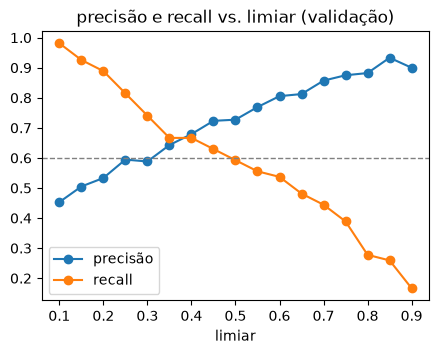

menor limiar com precisão >= 0,6: 0.35  precisão=0.643  recall=0.667


In [20]:
# 2. Limiar com restrição: menor limiar com precisão >= 0,6 na validação
import matplotlib.pyplot as plt

thr_sweep = np.arange(0.10, 0.901, 0.05)
rows2 = [{'t': round(t, 2),
          'precision': precision_score(y_val, (proba_val >= t).astype(int), zero_division=0),
          'recall': recall_score(y_val, (proba_val >= t).astype(int))}
         for t in thr_sweep]
curve = pd.DataFrame(rows2)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(curve['t'], curve['precision'], label='precisão', marker='o')
ax.plot(curve['t'], curve['recall'], label='recall', marker='o')
ax.axhline(0.6, color='gray', linestyle='--', linewidth=1)
ax.set_xlabel('limiar'); ax.legend(); ax.set_title('precisão e recall vs. limiar (validação)')
plt.show()

ok = curve[curve['precision'] >= 0.6]
best = ok.loc[ok['t'].idxmin()]
print(f"menor limiar com precisão >= 0,6: {best['t']:.2f}  precisão={best['precision']:.3f}  recall={best['recall']:.3f}")


**Resposta:** O menor limiar com precisão ≥ 0,6 na validação é **0,35** (precisão 0,643,
recall 0,667). Comparado ao limiar 0,10 que o F2 escolheu na simulação do Passo 9 (recall 0,981,
mas precisão só 0,453), a restrição de precisão é bem mais conservadora: troca quase todo o recall
por uma taxa de alarmes falsos administrável — reflete a mesma régua precisão/recall vista no
Passo 9, agora de trás para frente (fixando um piso de precisão em vez de otimizar um F-beta).


In [21]:
# 3. Pesos de classe: class_weight='balanced' no limiar 0,5 vs. sem pesos no limiar 0,3
logreg_bal = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                           LogisticRegression(max_iter=1000, class_weight='balanced')).fit(X_train, y_train)
pred_bal = logreg_bal.predict(X_val)
pred_03 = (proba_val >= 0.3).astype(int)

print("class_weight='balanced' @ 0,5:", {k: round(v, 3) for k, v in scores(y_val, pred_bal).items()})
print("sem pesos @ 0,3:              ", {k: round(v, 3) for k, v in scores(y_val, pred_03).items()})
print(f"discordam em {(pred_bal != pred_03).sum()} mulheres")


class_weight='balanced' @ 0,5: {'accuracy': 0.753, 'precision': 0.638, 'recall': 0.685, 'specificity': 0.79, 'F1': 0.661, 'balanced': 0.738, 'MCC': 0.468}
sem pesos @ 0,3:               {'accuracy': 0.727, 'precision': 0.588, 'recall': 0.741, 'specificity': 0.72, 'F1': 0.656, 'balanced': 0.73, 'MCC': 0.443}
discordam em 10 mulheres


**Resposta:** `class_weight='balanced'` no limiar 0,5 dá precisão **0,638**/recall **0,685**/
F1 **0,661**; abaixar o limiar para 0,3 sem pesos dá precisão **0,588**/recall **0,741**/F1
**0,656**. As duas formas de trocar precisão por recall não são a mesma coisa: `class_weight`
troca de forma mais moderada (recall sobe menos, mas precisão cai menos também) que baixar o
limiar para 0,3, e as duas versões discordam em **10** das 154 mulheres da validação — ajustar os
pesos desloca a fronteira de decisão de um jeito diferente de simplesmente mover o limiar sobre as
mesmas probabilidades.


In [22]:
# 4. Uma classe rara: descartando 90% do dígito 8 no treino e no teste
rng2 = np.random.default_rng(0)
idx_train8 = np.where(yd_train == 8)[0]
idx_test8 = np.where(yd_test == 8)[0]
keep_train8 = set(rng2.choice(idx_train8, size=int(len(idx_train8) * 0.10), replace=False))
keep_test8 = set(rng2.choice(idx_test8, size=int(len(idx_test8) * 0.10), replace=False))

mask_train = np.array([lbl != 8 or i in keep_train8 for i, lbl in enumerate(yd_train)])
mask_test = np.array([lbl != 8 or i in keep_test8 for i, lbl in enumerate(yd_test)])
Xd_train_r, yd_train_r = Xd_train[mask_train], yd_train[mask_train]
Xd_test_r, yd_test_r = Xd_test[mask_test], yd_test[mask_test]
print(f"dígito 8 no treino: {len(idx_train8)} -> {len(keep_train8)}   "
      f"no teste: {len(idx_test8)} -> {len(keep_test8)}")

digits_r = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xd_train_r, yd_train_r)
pred_dr = digits_r.predict(Xd_test_r)
for avg in ['macro', 'weighted']:
    print(f"{avg:8s} F1 {f1_score(yd_test_r, pred_dr, average=avg):.4f}")
print(f"acurácia {accuracy_score(yd_test_r, pred_dr):.4f}")
rec8 = recall_score(yd_test_r, pred_dr, average=None)
print(f"recall do dígito 8 agora: {rec8[8]:.3f} (com apenas {len(keep_test8)} exemplos de teste)")


dígito 8 no treino: 122 -> 12   no teste: 52 -> 5
macro    F1 0.9186
weighted F1 0.9771
acurácia 0.9797
recall do dígito 8 agora: 0.200 (com apenas 5 exemplos de teste)


**Resposta:** Mantendo só **10%** do dígito 8 (**12** de 122 no treino, **5** de 52 no
teste), o F1 **macro** despenca de 0,9814 para **0,9186**, enquanto o F1 **ponderado** quase não se
move (0,9816 → **0,9771**) — e a acurácia geral até sobe um pouco (**0,9797**). O recall do dígito 8
cai para **0,200** (só 1 das 5 imagens restantes acertada). O macro se mexe porque trata o dígito 8
como qualquer outra classe, com peso igual, mesmo tendo só 5 exemplos de teste agora; o ponderado
quase não se mexe porque esses 5 exemplos pesam pouquíssimo no total de ~540 imagens de teste — é a
mesma lógica do item 3 do "Para fechar a aula".


## Conclusões

- Acurácia sozinha engana numa triagem desbalanceada: a regressão logística tem 77,9% de acurácia
  na validação, mas captura só 59,3% (32 de 54) das mulheres com diabetes, e o `dummy majority`
  chega a 64,9% de acurácia sem identificar nenhuma mulher doente.
- A prevalência distorce a precisão sem que o modelo mude: a mesma logística, mesmo limiar, cai de
  precisão 0,727 (prevalência 34,9%) para precisão 0,200 numa validação simulada com prevalência
  4,8%; a acurácia balanceada (0,740) e o MCC (0,292) continuam enxergando o modelo como melhor que
  o acaso, diferente da acurácia bruta (que favorece o `dummy majority`, 95,2%).
- Baixar o limiar de 0,5 para 0,3 troca 10 falsos negativos por 16 falsos positivos (recall
  0,593 → 0,741, precisão 0,727 → 0,588); o F1 quase não registra essa troca (0,653 → 0,656), mas o
  F2 sim (0,615 → 0,704) — o β do F-beta é a régua que escolhe o limiar certo para o problema.
- Probabilidade mal calibrada custa caro em log loss mesmo vencendo em F1: o k-NN (k = 5) tem F1
  0,686 contra 0,653 da logística, mas log loss 1,290 contra 0,452, porque 3 mulheres com diabetes
  recebem probabilidade exatamente 0 (todas as 5 vizinhas sem diabetes); subir para k = 25 já basta
  para colocar a log loss (0,443) abaixo da baseline `dummy prior` (0,648).
- No único teste permitido, o limiar 0,3 escolhido na validação deu recall 0,796 (43 de 54) e F2
  0,749 — parecido com a validação (F2 0,704), dentro do ruído esperado para 154 mulheres; a
  acurácia no teste (0,747) ficou, nesta amostra específica, acima da acurácia com limiar 0,5
  (0,708), o que mostra que "baixar o limiar sempre reduz a acurácia" é só uma tendência média, não
  uma lei por amostra.
- Em multiclasse, F1 macro e ponderado só discordam quando as classes são desiguais: com os
  dígitos originais (quase balanceados) os dois ficam a 0,0002 um do outro (0,9814 vs. 0,9816); ao
  reduzir o dígito 8 para 5 exemplos de teste, o macro cai para 0,9186 (sensível à classe rara) e o
  ponderado quase não se move (0,9771), porque pesa pelo tamanho de cada classe.
